<a href="https://colab.research.google.com/github/ArifahZhafirah/PCVK26_04_Arifah/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [83]:
#CATATAN: jalankan sel ini hanya jika muncul error 'cv2 has no attribute CascadeClassifier'
#setelah selesai, klik Runtime > Restart session, lalu lanjut dari sel berikutnya (jangan jalankan sel ini lagi)
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install opencv-python==4.11.0.86

Found existing installation: opencv-python 4.11.0.86
Uninstalling opencv-python-4.11.0.86:
  Successfully uninstalled opencv-python-4.11.0.86
  Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.11.0.86-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (63.0 MB)


#D1. Praktikum Deteksi Obyek Dasar

1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, buat notebook baru dan beri nama “Week10.ipynb”.
Kemudian import beberapa library dan akses folder yang ada di Drive Anda dengan cara
sebagai berikut.

#Object Detection
Metode yang digunakan:
1. Template Matching
2. Edge Detection
3. Corner Detection
4. Grid Detection
5. Contour Detection

In [1]:
import cv2 as cv

import numpy as np
from matplotlib import pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Implementasikan 6 metode template matching pada OpenCV dengan
menggunakan gambar cats_and_bunnies.jpg dan cat2_templatejpg.jpg sebagai
citra template.

In [3]:
folder = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/Images Object Detection/'

img_bgr = cv.imread(folder + 'cats_and_bunnies.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
template = cv.imread(folder + 'cat2_templatejpg.jpg', 0)
h, w = template.shape

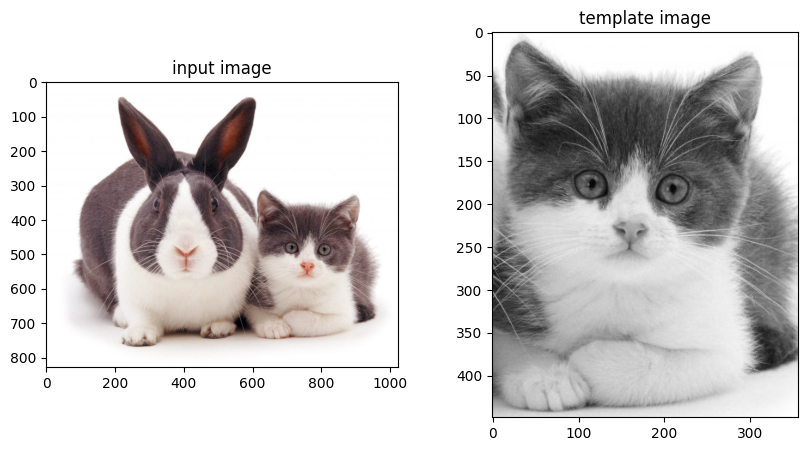

In [4]:
plt.figure(figsize=(10,5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

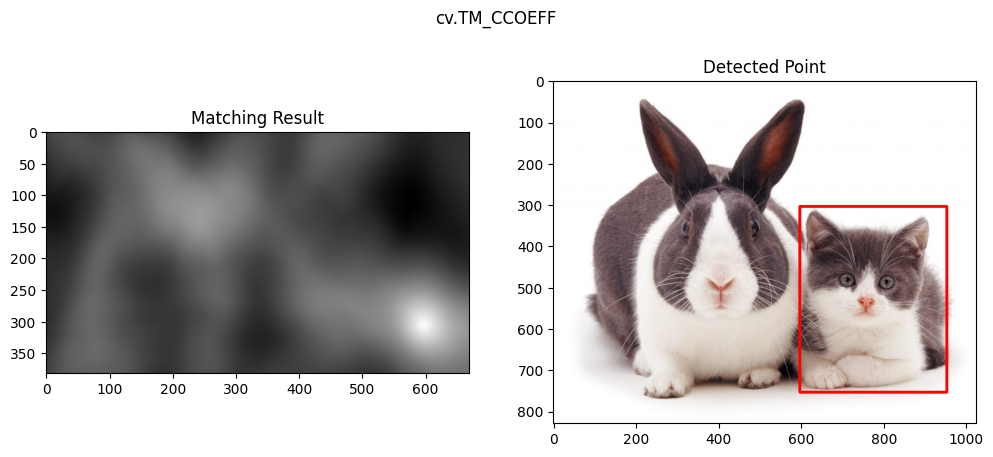

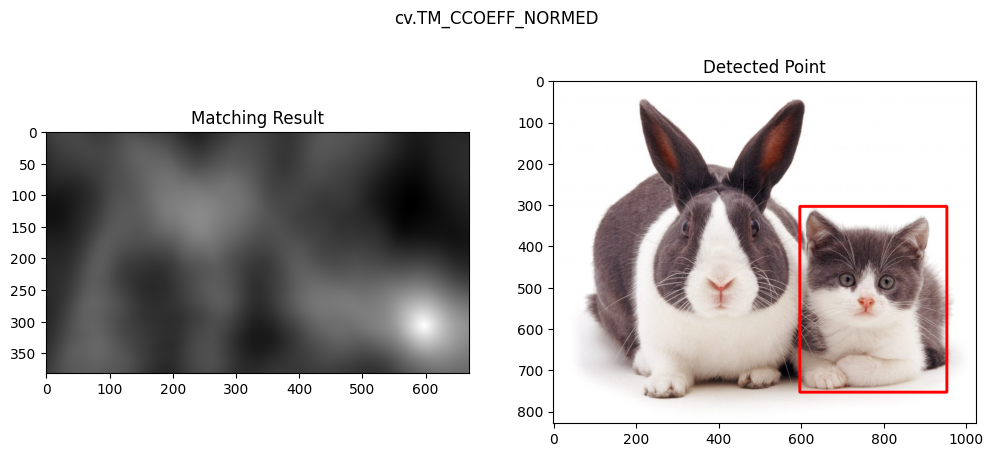

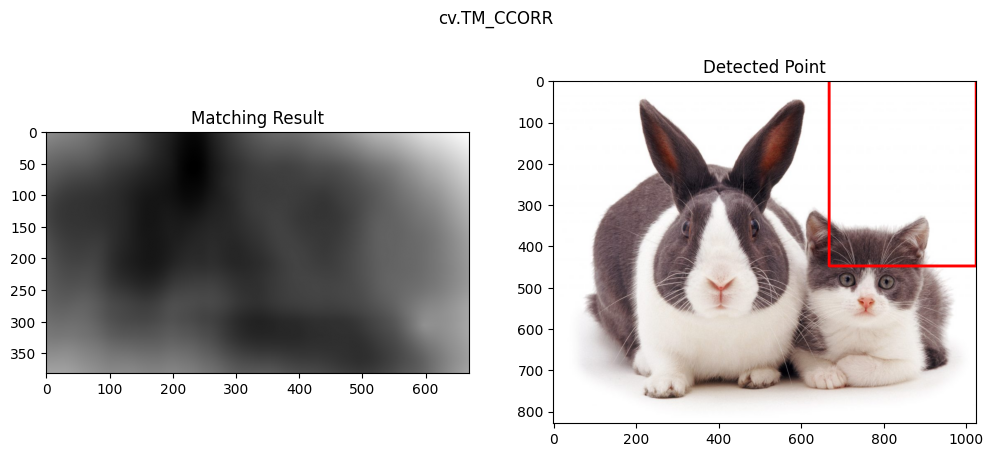

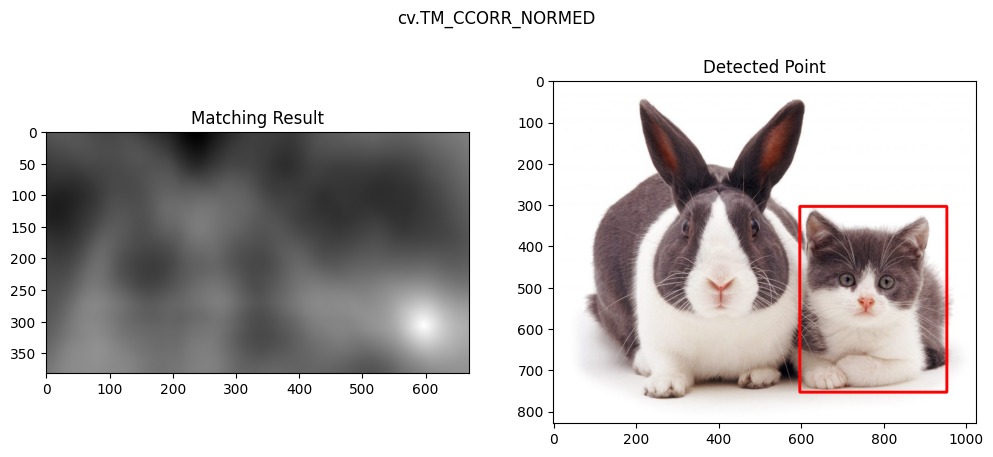

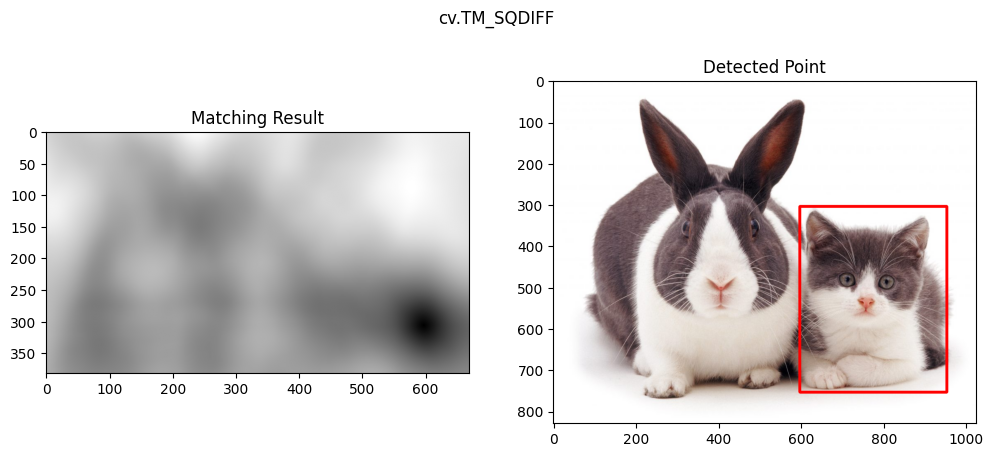

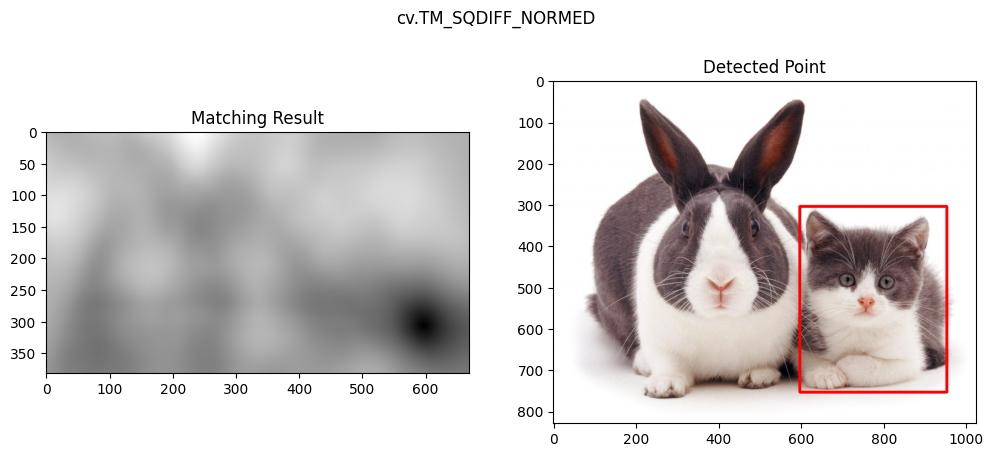

In [5]:
metode = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
          'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for m in metode:
    img = img_rgb.copy()
    method = eval(m)

    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img, top_left, bottom_right, (255,0,0), 5)

    plt.figure(figsize=(12,5))
    plt.suptitle(m)
    plt.subplot(121), plt.imshow(res, cmap='gray'), plt.title('Matching Result')
    plt.subplot(122), plt.imshow(img), plt.title('Detected Point')
    plt.show()

3. Implementasikan konsep template matching tanpa menggunakan library OpenCV untuk

multiple object, menggunakan gambar bahrain.jpg untuk citra masukan dan bahrain-
template.jpg sebagai citra template, sehingga menghasilkan output sebagai berikut:

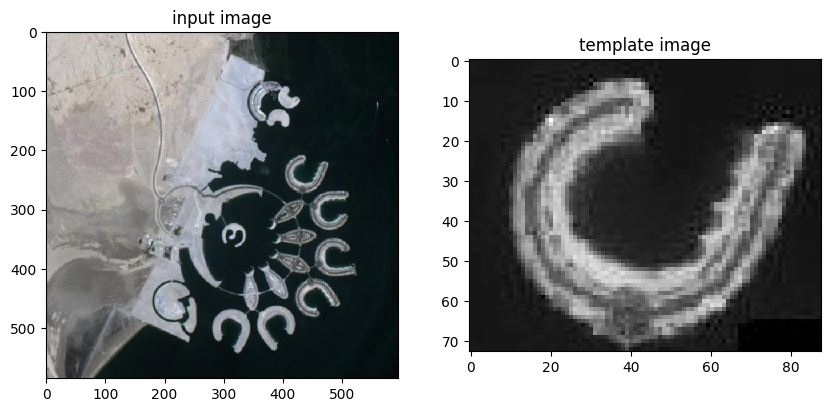

In [6]:
bahrain = cv.imread(folder + 'bahrain.jpg')
bahrain_rgb = cv.cvtColor(bahrain, cv.COLOR_BGR2RGB)
bahrain_gray = cv.cvtColor(bahrain, cv.COLOR_BGR2GRAY).astype(np.float32)
temp = cv.imread(folder + 'bahrain-template.jpg', 0).astype(np.float32)
th, tw = temp.shape

plt.figure(figsize=(10,5))
plt.subplot(121), plt.imshow(bahrain_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(temp, cmap='gray'), plt.title('template image')
plt.show()

In [7]:
H, W = bahrain_gray.shape
R = np.zeros((H - th + 1, W - tw + 1))

t = temp - temp.mean()
t_norm = np.sqrt(np.sum(t ** 2))

for y in range(R.shape[0]):
    for x in range(R.shape[1]):
        patch = bahrain_gray[y:y+th, x:x+tw]
        p = patch - patch.mean()
        p_norm = np.sqrt(np.sum(p ** 2))
        if p_norm * t_norm != 0:
            R[y, x] = np.sum(p * t) / (p_norm * t_norm)

In [8]:
print("nilai R tertinggi:", R.max())

for threshold in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55]:
    ys, xs = np.where(R >= threshold)
    urutan = np.argsort(R[ys, xs])[::-1]
    hasil = []
    for i in urutan:
        x, y = xs[i], ys[i]
        dekat = False
        for (hx, hy) in hasil:
            if abs(x - hx) < tw // 2 and abs(y - hy) < th // 2:
                dekat = True
                break
        if not dekat:
            hasil.append((x, y))
    print("threshold", threshold, "-> jumlah objek:", len(hasil))

nilai R tertinggi: 0.9641707539558411
threshold 0.3 -> jumlah objek: 17
threshold 0.35 -> jumlah objek: 13
threshold 0.4 -> jumlah objek: 7
threshold 0.45 -> jumlah objek: 6
threshold 0.5 -> jumlah objek: 3
threshold 0.55 -> jumlah objek: 2


jumlah objek terdeteksi: 6


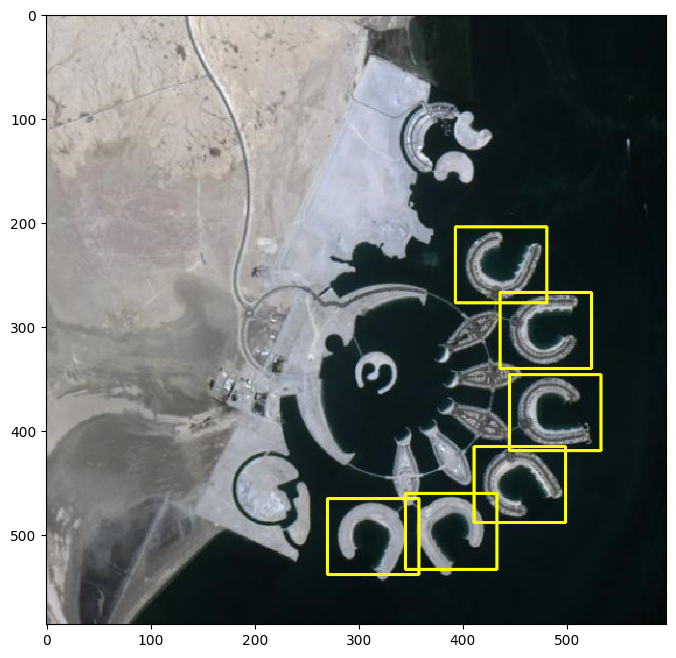

In [9]:
threshold = 0.45
ys, xs = np.where(R >= threshold)

urutan = np.argsort(R[ys, xs])[::-1]
hasil = []
for i in urutan:
    x, y = xs[i], ys[i]
    dekat = False
    for (hx, hy) in hasil:
        if abs(x - hx) < tw // 2 and abs(y - hy) < th // 2:
            dekat = True
            break
    if not dekat:
        hasil.append((x, y))

img = bahrain_rgb.copy()
for (x, y) in hasil:
    cv.rectangle(img, (x, y), (x + tw, y + th), (255,255,0), 2)

print("jumlah objek terdeteksi:", len(hasil))
plt.figure(figsize=(8,8))
plt.imshow(img)
plt.show()

4. Implementasikan metode Sobel Edge Detection, Canny Edge Detection,
dan Laplacian Edge Detection pada OpenCV dengan menggunakan
gambar car-park.jpg, sehingga menghasilkan luaran sebagai berikut:



In [10]:
car = cv.imread(folder + 'car-park.jpg')
car_rgb = cv.cvtColor(car, cv.COLOR_BGR2RGB)
car_gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)

a. Sobel Edge Detection

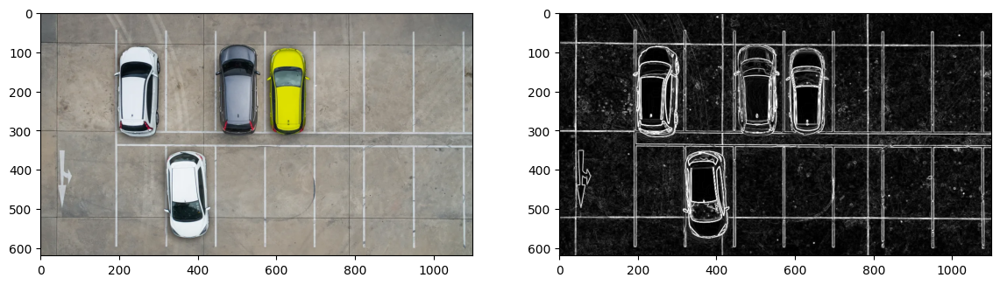

In [11]:
sobelx = cv.Sobel(car_gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(car_gray, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobelx, sobely))

plt.figure(figsize=(14,5))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(sobel, cmap='gray')
plt.show()

b. Canny Edge Detection

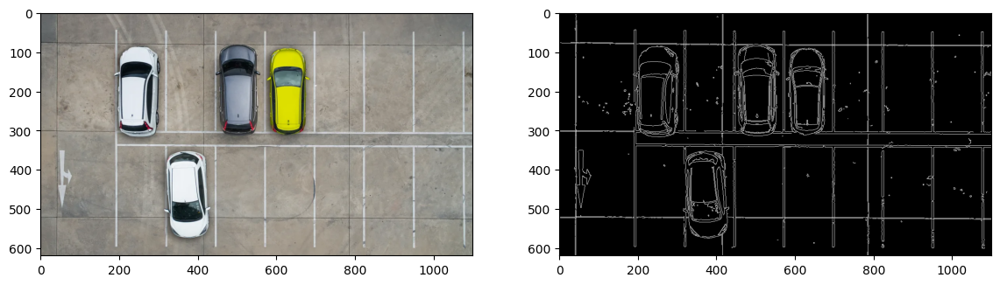

In [12]:
canny = cv.Canny(car_gray, 100, 200)

plt.figure(figsize=(14,5))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(canny, cmap='gray')
plt.show()

c. Laplacian Edge Detection

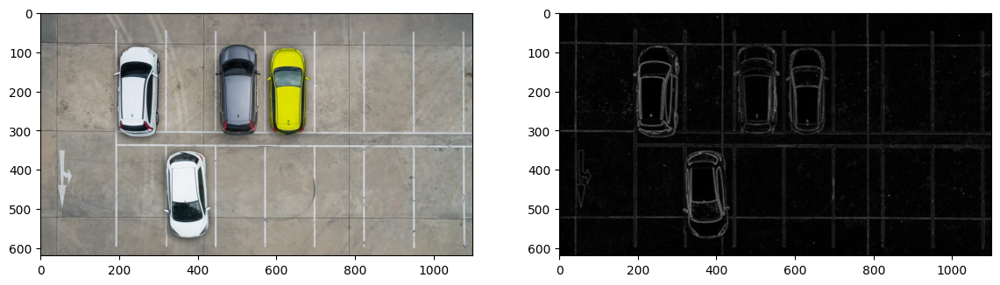

In [13]:
blur = cv.GaussianBlur(car_gray, (3,3), 0)
laplacian = cv.convertScaleAbs(cv.Laplacian(blur, cv.CV_64F))

plt.figure(figsize=(14,5))
plt.subplot(121), plt.imshow(car_rgb)
plt.subplot(122), plt.imshow(laplacian, cmap='gray')
plt.show()

5. Implementasikan metode Harris Corner Detection dan Shi-Tomasi

Detection pada OpenCV dengan menggunakan gambar chess-
board.jpg, sehingga menghasilkan luaran sebagai berikut:

a. Harris Corner Detection

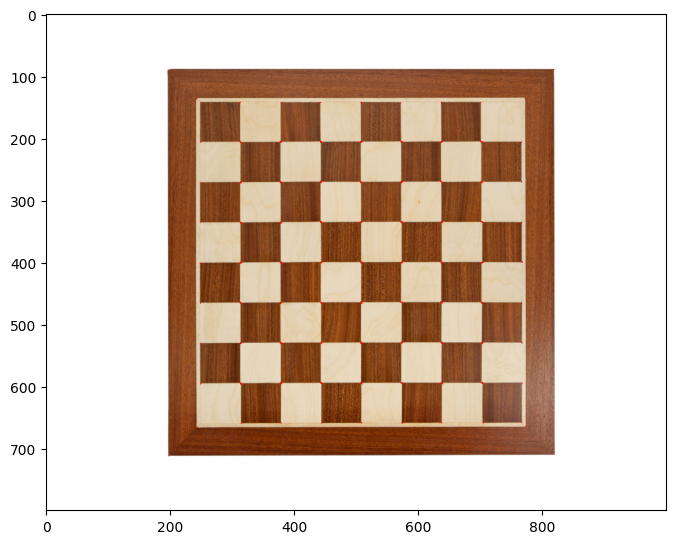

In [14]:
chess = cv.imread(folder + 'chess-board.jpg')
chess_rgb = cv.cvtColor(chess, cv.COLOR_BGR2RGB)
chess_gray = np.float32(cv.cvtColor(chess, cv.COLOR_BGR2GRAY))

dst = cv.cornerHarris(chess_gray, 2, 3, 0.04)

img = chess_rgb.copy()
img[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.show()

b. Shi-Tomasi Detection

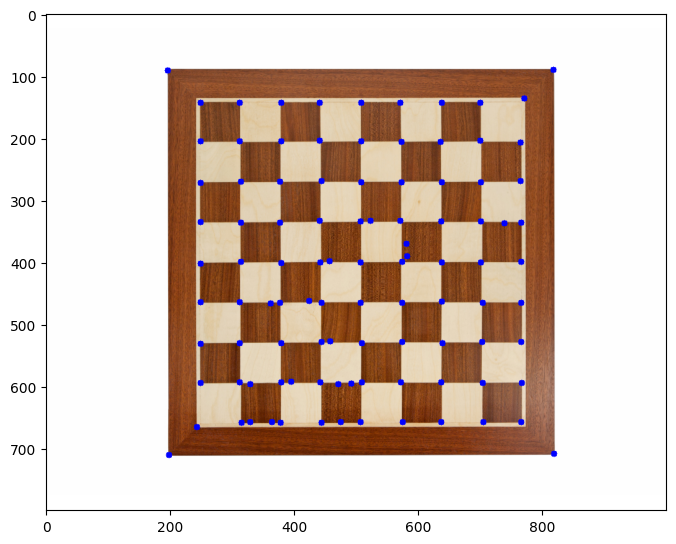

In [15]:

chess_gray8 = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

corners = cv.goodFeaturesToTrack(chess_gray8, 100, 0.01, 10)
corners = np.int32(corners)

img = chess_rgb.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(img, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.show()

6. Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg. Tahapan proses grid detection sesuai yang
terdapat pada ulasan teori, sehingga menghasilkan luaran sebagai berikut:

In [16]:
sudoku = cv.imread(folder + 'sudoku.jpg')
sudoku_rgb = cv.cvtColor(sudoku, cv.COLOR_BGR2RGB)
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

edges = cv.Canny(sudoku_gray, 50, 150)

kernel = np.ones((3,3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)

edges = cv.erode(edges, kernel, iterations=1)

In [17]:
for thr in [150, 200, 250, 300, 350, 400]:
    lines = cv.HoughLines(edges, 1, np.pi / 180, thr)
    if lines is None:
        print("threshold", thr, "-> tidak ada garis")
        continue

    garis_final = []
    for line in lines:
        rho, theta = line[0]
        mirip = False
        for (r, t) in garis_final:
            if abs(rho - r) < 20 and abs(theta - t) < np.pi / 36:
                mirip = True
                break
        if not mirip:
            garis_final.append((rho, theta))
    print("threshold", thr, "-> sebelum digabung:", len(lines), "sesudah digabung:", len(garis_final))

threshold 150 -> sebelum digabung: 2422 sesudah digabung: 170
threshold 200 -> sebelum digabung: 199 sesudah digabung: 37
threshold 250 -> sebelum digabung: 54 sesudah digabung: 23
threshold 300 -> sebelum digabung: 17 sesudah digabung: 14
threshold 350 -> sebelum digabung: 1 sesudah digabung: 1
threshold 400 -> tidak ada garis


jumlah garis sebelum digabung: 85
sebelum dibersihkan -> horizontal: 10 vertikal: 11
jumlah garis vertikal: 10
jumlah garis total: 20


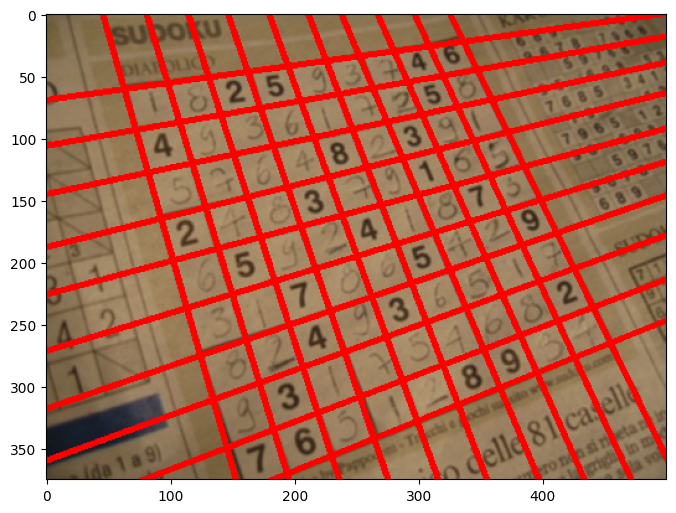

In [18]:
folder = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/Images Object Detection/'

sudoku = cv.imread(folder + 'sudoku.jpg')
sudoku_rgb = cv.cvtColor(sudoku, cv.COLOR_BGR2RGB)
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)
tinggi_gambar = sudoku_rgb.shape[0]

thr_hough = 230
jarak_rho = 12
tebal = 4

edges = cv.Canny(sudoku_gray, 50, 150)
kernel = np.ones((3,3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
edges = cv.erode(edges, kernel, iterations=1)

lines = cv.HoughLines(edges, 1, np.pi / 180, thr_hough)
print("jumlah garis sebelum digabung:", len(lines))

garis_final = []
for line in lines:
    rho, theta = line[0]
    if not (theta < np.pi / 6 or theta > 5 * np.pi / 6 or (np.pi / 3 < theta < 2 * np.pi / 3)):
        continue
    mirip = False
    for (r, t) in garis_final:
        if abs(rho - r) < jarak_rho and abs(theta - t) < np.pi / 36:
            mirip = True
            break
    if not mirip:
        garis_final.append((rho, theta))

vertikal = []
horizontal = []
for (rho, theta) in garis_final:
    if np.pi / 3 < theta < 2 * np.pi / 3:
        horizontal.append((rho, theta))
    else:
        x_tengah = (rho - (tinggi_gambar / 2) * np.sin(theta)) / np.cos(theta)
        vertikal.append((x_tengah, rho, theta))
vertikal.sort()
print("sebelum dibersihkan -> horizontal:", len(horizontal), "vertikal:", len(vertikal))

vertikal_bersih = []
for v in vertikal:
    if len(vertikal_bersih) == 0 or v[0] - vertikal_bersih[-1][0] >= 28:
        vertikal_bersih.append(v)

garis_final = horizontal + [(v[1], v[2]) for v in vertikal_bersih]
print("jumlah garis vertikal:", len(vertikal_bersih))
print("jumlah garis total:", len(garis_final))

img = sudoku_rgb.copy()
for (rho, theta) in garis_final:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(img, (x1, y1), (x2, y2), (255, 0, 0), tebal)

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.show()

7. Implementasikan fungsi findContours() pada OpenCV untuk contour detection
dengan menggunakan gambar laptop.jpg, sehingga menghasilkan luaran
sebagai berikut:

jumlah kontur yang ditemukan: 48


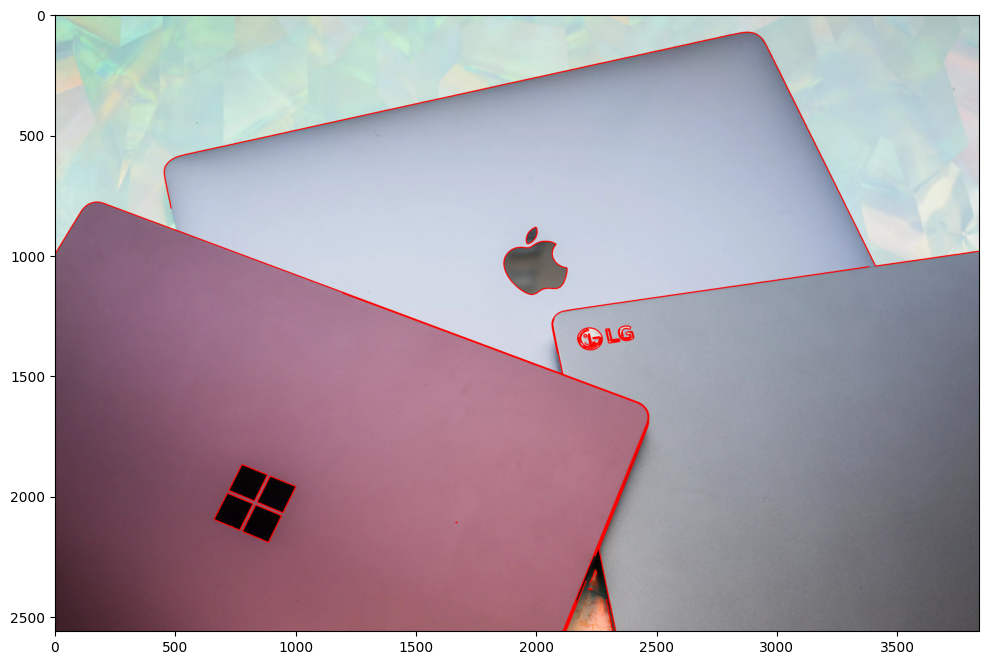

In [19]:
folder = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/Images Object Detection/'

img_bgr = cv.imread(folder + 'laptop.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

biner = cv.Canny(img_blur, 50, 150)

contours, hierarchy = cv.findContours(biner, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
print('jumlah kontur yang ditemukan:', len(contours))

img_kontur = img_rgb.copy()
tebal = 3
cv.drawContours(img_kontur, contours, -1, (255, 0, 0), tebal)

plt.figure(figsize=(12, 8))
plt.imshow(img_kontur)
plt.show()

#D2. Praktikum Feature Matching dan Face Detection

In [20]:
import cv2 as cv
print(cv.__version__)
print(hasattr(cv, 'CascadeClassifier'))
print(hasattr(cv, 'SIFT_create'))

4.11.0
True
True


In [21]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

folder_induk = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/'
folder_facedet = folder_induk + 'facedet/'
folder_cascade = folder_induk + 'haarcascades/'

cascade_wajah = cv.CascadeClassifier(folder_cascade + 'haarcascade_frontalface_alt.xml')
cascade_kucing = cv.CascadeClassifier(folder_cascade + 'haarcascade_frontalcatface.xml')
cascade_mata = cv.CascadeClassifier(folder_cascade + 'haarcascade_eye.xml')
cascade_senyum = cv.CascadeClassifier(folder_cascade + 'haarcascade_smile.xml')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


8. Lakukan Face Detection untuk image object lain yang tersedia pada
(/images/facedet). Tampilkan seperti pada contoh berikut.


prabowo.jpg -> jumlah wajah: 1


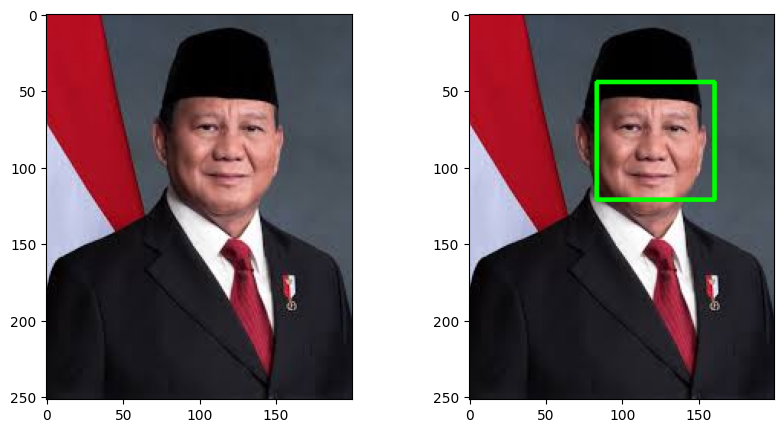

kartini.jpg -> jumlah wajah: 1


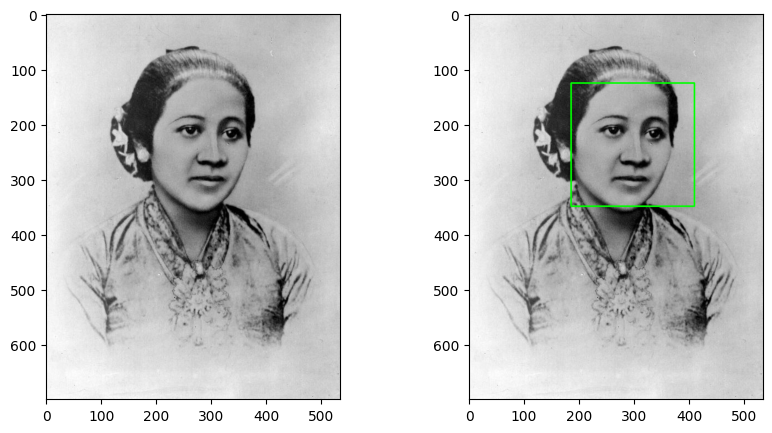

kucing.jpg -> jumlah wajah: 0


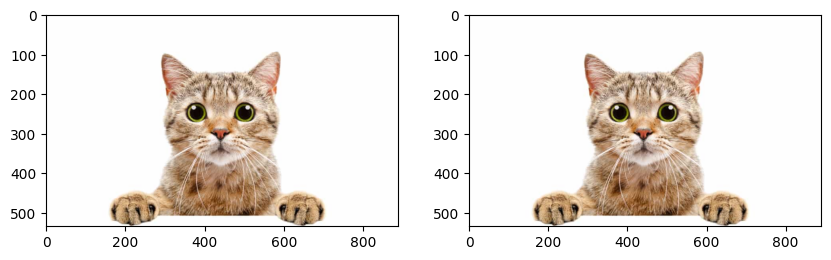

mask.png -> jumlah wajah: 5


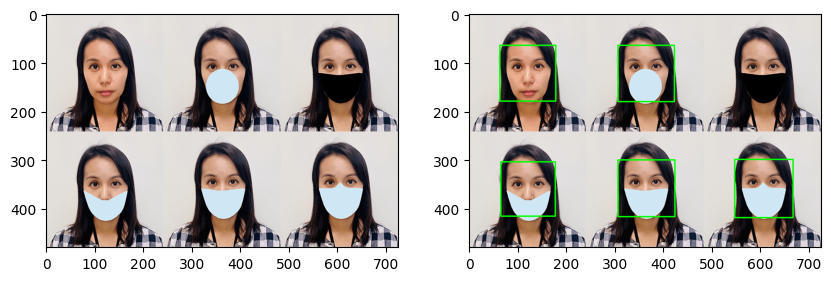

mjordan.jpg -> jumlah wajah: 1


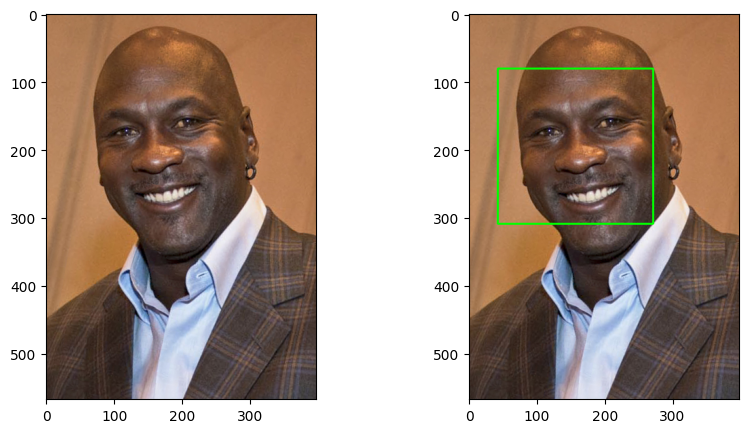

solvayconf.jpg -> jumlah wajah: 28


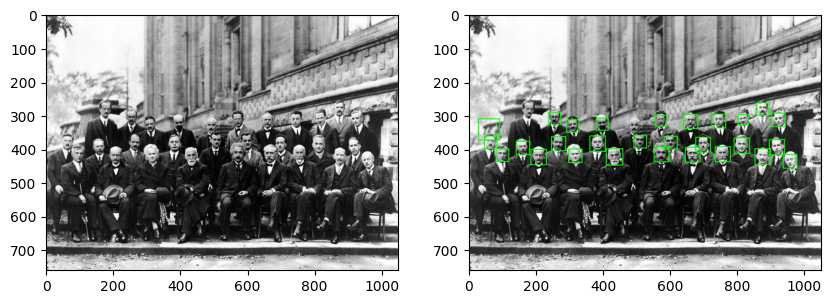

In [22]:
daftar_gambar = ['prabowo.jpg', 'kartini.jpg', 'kucing.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

for nama in daftar_gambar:
    img_bgr = cv.imread(folder_facedet + nama)
    img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

    roi_wajah = cascade_wajah.detectMultiScale(img_gray)
    print(nama, '-> jumlah wajah:', len(roi_wajah))

    img_hasil = img_rgb.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(img_hasil, (x, y), (x+w, y+h), (0, 255, 0), 2)

    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(img_rgb)
    plt.subplot(122), plt.imshow(img_hasil)
    plt.show()

Perhatikan pada hasil face detection diatas. Secara keseluruhan, face detection dapat dilakukan dengan baik, bahkan untuk image berupa gambar bukan foto, wajah
bermasker, atau wajah yang berukuran kecil (solvay).

9. Pada soal sebelumnya, wajah kucing tidak bisa dideteksi dengan baik. Lakukan
deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing.
Petunjuk pada soal ini, perhatikan pretrained features yang telah disediakan
OpenCV. Gunakan xml yang ada jika memang telah disediakan. Jika belum ada,
coba cari dengan searching melalui search engines.

jumlah wajah kucing sebelum disaring: 2


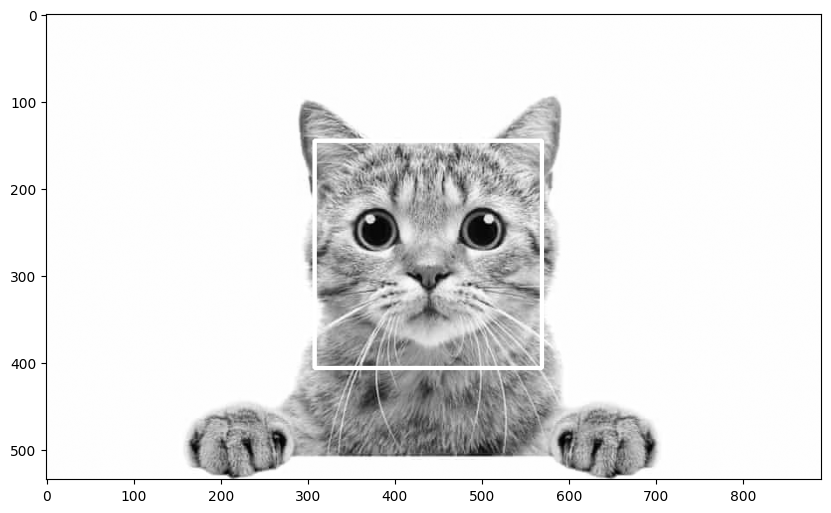

In [23]:
kucing = cv.imread(folder_facedet + 'kucing.jpg')
kucing_gray = cv.cvtColor(kucing, cv.COLOR_BGR2GRAY)

roi_kucing = cascade_kucing.detectMultiScale(kucing_gray, scaleFactor=1.1, minNeighbors=3)
print('jumlah wajah kucing sebelum disaring:', len(roi_kucing))

x, y, w, h = max(roi_kucing, key=lambda r: r[2] * r[3])
cv.rectangle(kucing_gray, (x, y), (x+w, y+h), (255, 255, 255), 3)

plt.figure(figsize=(10, 10))
plt.imshow(kucing_gray, cmap='gray')
plt.show()

10.Cobakan juga untuk eyes detection pada wajah Pak Prabowo:

minNeighbors yang dipakai: 5 | jumlah mata: 2


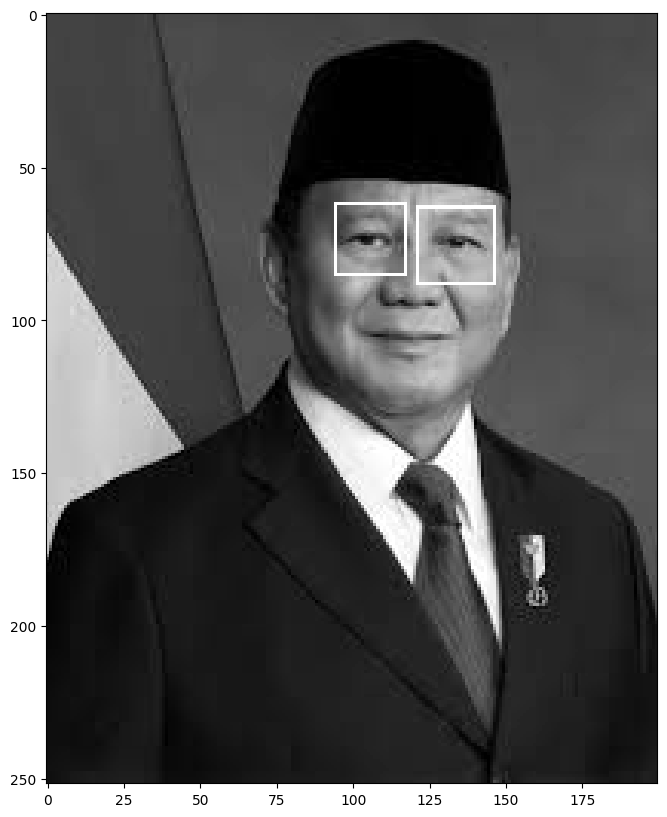

In [24]:
wajah_img = cv.imread(folder_facedet + 'prabowo.jpg', 0)
roi_wajah = cascade_wajah.detectMultiScale(wajah_img)

for (x, y, w, h) in roi_wajah:
    wajah_atas = wajah_img[y:y+int(0.6*h), x:x+w]

    for tetangga in [5, 4, 3, 2, 1]:
        roi_mata = cascade_mata.detectMultiScale(wajah_atas, scaleFactor=1.05, minNeighbors=tetangga)
        if len(roi_mata) >= 2:
            break
    print('minNeighbors yang dipakai:', tetangga, '| jumlah mata:', len(roi_mata))

    roi_mata = sorted(roi_mata, key=lambda r: r[2] * r[3], reverse=True)[:2]

    for (ex, ey, ew, eh) in roi_mata:
        cv.rectangle(wajah_img, (x+ex, y+ey), (x+ex+ew, y+ey+eh), (255, 255, 255), 1)

plt.figure(figsize=(10, 10))
plt.imshow(wajah_img, cmap='gray')
plt.show()

11.Lakukan deteksi senyuman pada gambar people:

jumlah wajah: 1


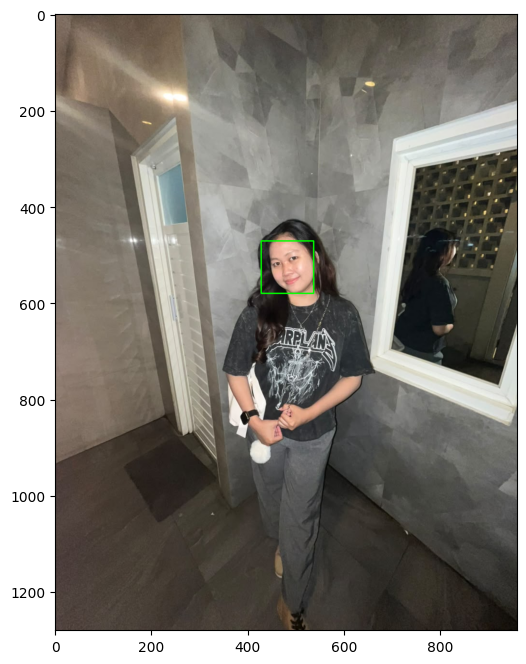

In [25]:
people_bgr = cv.imread(folder_facedet + 'Arifah_Image.jpeg')
people_gray = cv.cvtColor(people_bgr, cv.COLOR_BGR2GRAY)
people_rgb = cv.cvtColor(people_bgr, cv.COLOR_BGR2RGB)

roi_wajah = cascade_wajah.detectMultiScale(people_gray)
print('jumlah wajah:', len(roi_wajah))

for (x, y, w, h) in roi_wajah:
    cv.rectangle(people_rgb, (x, y), (x+w, y+h), (0, 255, 0), 2)

    wajah = people_gray[y:y+h, x:x+w]
    roi_senyum = cascade_senyum.detectMultiScale(wajah, scaleFactor=1.7, minNeighbors=20)
    for (sx, sy, sw, sh) in roi_senyum:
        cv.rectangle(people_rgb, (x+sx, y+sy), (x+sx+sw, y+sy+sh), (255, 0, 0), 2)

plt.figure(figsize=(14, 8))
plt.imshow(people_rgb)
plt.show()

12.Lakukan Face Tracking menggunakan Google Colab. Petunjuk, Tutorial lengkap
tentang akses kamera dan FaceDetection pada google colab dapat dilihat di link
berikut: https://www.youtube.com/watch?v=YjWh7QvVH60

In [26]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

<IPython.core.display.Javascript object>

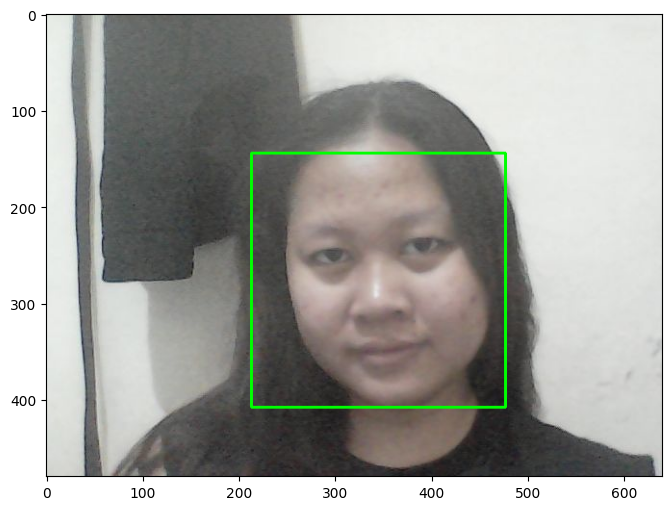

In [27]:
foto = take_photo()

kamera_bgr = cv.imread(foto)
kamera_gray = cv.cvtColor(kamera_bgr, cv.COLOR_BGR2GRAY)
kamera_rgb = cv.cvtColor(kamera_bgr, cv.COLOR_BGR2RGB)

roi_wajah = cascade_wajah.detectMultiScale(kamera_gray)
for (x, y, w, h) in roi_wajah:
    cv.rectangle(kamera_rgb, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(kamera_rgb)
plt.show()

13.Lakukan Blurring pada bagian wajah yang terdeteksi. Berikut contoh keluaran
yang diharapkan. Petunjuk: anda dapat menggunakan cv.medianBlur untuk
melakukan Blurring

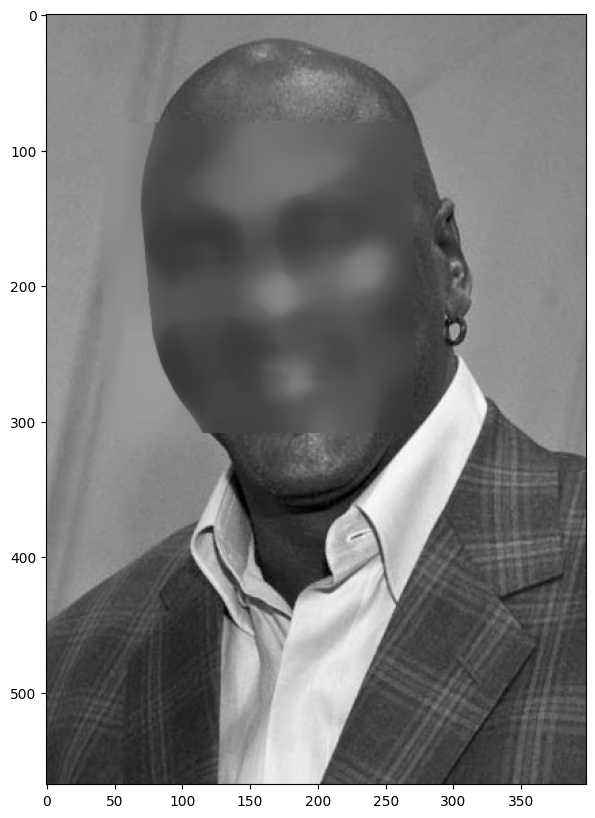

In [28]:
jordan = cv.imread(folder_facedet + 'mjordan.jpg', 0)
roi_wajah = cascade_wajah.detectMultiScale(jordan)

for (x, y, w, h) in roi_wajah:
    wajah = jordan[y:y+h, x:x+w]
    wajah_blur = cv.medianBlur(wajah, 35)
    jordan[y:y+h, x:x+w] = wajah_blur

plt.figure(figsize=(8, 10))
plt.imshow(jordan, cmap='gray')
plt.show()

14.Mengolah gambar KTM masing-masing

a. Berikut ini contoh KTM

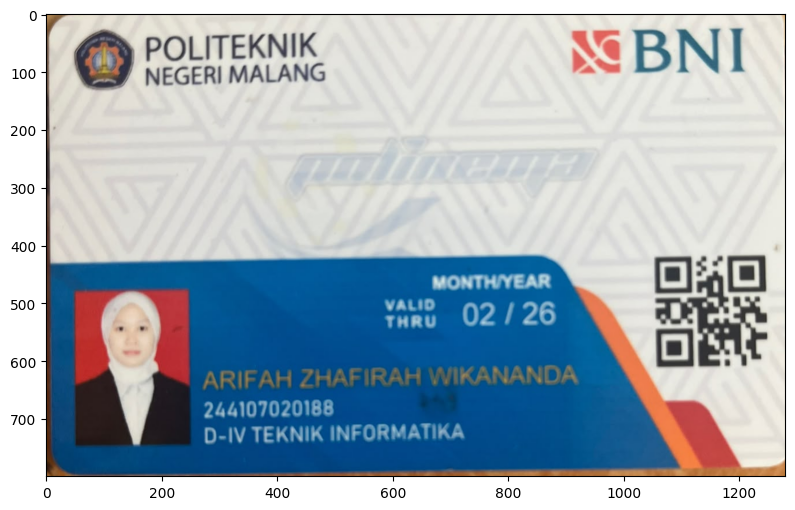

In [29]:
file_ktm = folder_facedet + 'KTM1d.jpeg'
file_ktm_barang = folder_facedet + 'ktm_dengan_barang.jpg'

ktm_bgr = cv.imread(file_ktm)
ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(ktm_rgb)
plt.show()

b. Tampilkan Foto KTM seperti contoh berikut ini:

jumlah wajah di KTM: 3
ukuran foto KTM: (160, 198, 3)


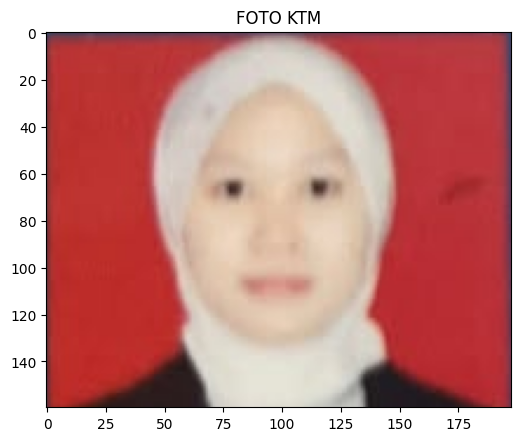

In [30]:
roi_wajah = cascade_wajah.detectMultiScale(ktm_gray, scaleFactor=1.05, minNeighbors=2)
print('jumlah wajah di KTM:', len(roi_wajah))

lebar_ktm = ktm_gray.shape[1]
kandidat = [r for r in roi_wajah if r[0] < lebar_ktm / 2]

x, y, w, h = max(kandidat, key=lambda r: r[2] * r[3])

m = int(0.8 * w)
ya = max(0, y - m)
yb = min(ktm_rgb.shape[0], y + h + m)
xa = max(0, x - m)
xb = min(ktm_rgb.shape[1], x + w + m)
area = ktm_rgb[ya:yb, xa:xb]

hsv = cv.cvtColor(area, cv.COLOR_RGB2HSV)
merah1 = cv.inRange(hsv, (0, 120, 100), (10, 255, 255))
merah2 = cv.inRange(hsv, (170, 120, 100), (180, 255, 255))
mask = cv.bitwise_or(merah1, merah2)

mask = cv.morphologyEx(mask, cv.MORPH_OPEN, np.ones((5, 5), np.uint8))

contours, hierarchy = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
terbesar = max(contours, key=cv.contourArea)
besar = [c for c in contours if cv.contourArea(c) > 0.1 * cv.contourArea(terbesar)]
bx, by, bw, bh = cv.boundingRect(np.vstack(besar))

foto = area[by:by+bh, bx:bx+bw]
mask_foto = mask[by:by+bh, bx:bx+bw] > 0

kolom = np.where(mask_foto.mean(axis=0) > 0.15)[0]
baris = np.where(mask_foto.mean(axis=1) > 0.15)[0]
foto_ktm = foto[baris[0]:baris[-1]+1, kolom[0]:kolom[-1]+1]
print('ukuran foto KTM:', foto_ktm.shape)

plt.figure(figsize=(6, 6))
plt.imshow(foto_ktm)
plt.title('FOTO KTM')
plt.show()

c. Lakukan Deteksi Obyek KTM pada gambar yang berisi KTM bersama
barang lain dengan menggunakan Konsep Feature Matching

In [31]:
print(file_ktm_barang)
print(os.path.exists(file_ktm_barang))
print(os.listdir(folder_facedet))

/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/facedet/ktm_dengan_barang.jpg
False
['KTM1d.jpeg', 'prabowo.jpg', 'Arifah_Image.jpeg', 'mjordan.jpg', 'kartini.jpg', 'mask.png', 'solvayconf.jpg', 'many_cereals.jpg', 'kucing.jpg', 'reeses_puffs.png', 'jokowi.jpg']


In [32]:
file_ktm = folder_facedet + 'KTM1d.jpeg'
file_ktm_barang = folder_facedet + 'KTM1d.jpeg'

ktm_bgr = cv.imread(file_ktm)
ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2GRAY)

print('KTM terbaca:', ktm_bgr is not None)
print('foto KTM bersama barang ada:', os.path.exists(file_ktm_barang))
print('ukuran KTM:', ktm_bgr.shape)

KTM terbaca: True
foto KTM bersama barang ada: True
ukuran KTM: (800, 1280, 3)


jumlah good matches: 1363
jumlah matches: 1363


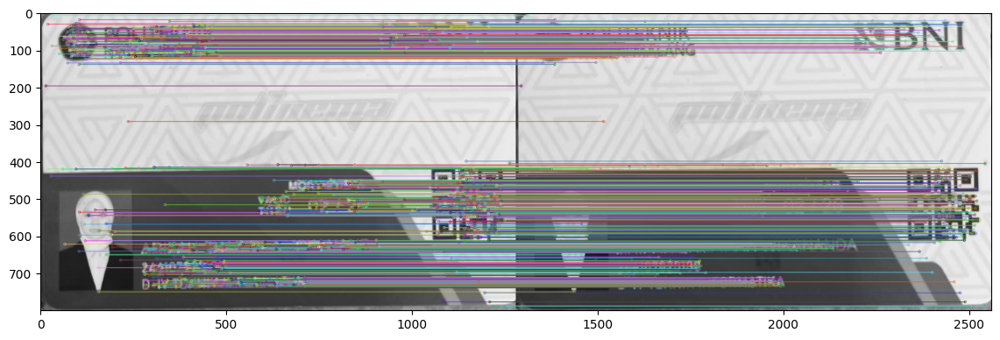

In [33]:
ktm = cv.imread(file_ktm, 0)
barang = cv.imread(file_ktm_barang, 0)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(ktm, None)
kp2, des2 = sift.detectAndCompute(barang, None)
bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good = []

for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

print('jumlah good matches:', len(good))
print('jumlah matches:', len(matches))

sift_matches = cv.drawMatchesKnn(ktm, kp1, barang, kp2, good, None, flags=2)
plt.figure(figsize=(14, 10))
plt.imshow(sift_matches, cmap='gray')
plt.show()

#D3. Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN

In [34]:
import os
from google.colab import drive
drive.mount('/content/drive')

folder_induk = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/'

for angka in range(10):
    os.makedirs(folder_induk + 'dataset/training/' + str(angka), exist_ok=True)
os.makedirs(folder_induk + 'dataset/testing/KTM', exist_ok=True)

print(sorted(os.listdir(folder_induk + 'dataset/training')))
print(os.listdir(folder_induk + 'dataset/testing'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
['KTM']


In [35]:
for angka in range(10):
    isi = os.listdir(folder_induk + 'dataset/training/' + str(angka))
    print(angka, '->', len(isi), 'gambar')

print('testing/KTM ->', sorted(os.listdir(folder_induk + 'dataset/testing/KTM')))

0 -> 1 gambar
1 -> 1 gambar
2 -> 1 gambar
3 -> 1 gambar
4 -> 1 gambar
5 -> 1 gambar
6 -> 1 gambar
7 -> 1 gambar
8 -> 1 gambar
9 -> 1 gambar
testing/KTM -> ['01.png', '02.png', '03.png', '04.png', '05.png', '06.png', '07.png', '08.png', '09.png', '10.png', '11.png', '12.png', 'KTM1d.jpeg']


In [36]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = folder_induk + "dataset/training"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img),
                                   cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

9: 100%|██████████| 1/1 [00:00<00:00, 116.63it/s]

jumlah data : 10
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [37]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.1250 - loss: 2.3078 - val_accuracy: 0.0000e+00 - val_loss: 2.7849
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 535ms/step - accuracy: 0.1250 - loss: 2.2026 - val_accuracy: 0.0000e+00 - val_loss: 3.1383
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 572ms/step - accuracy: 0.1250 - loss: 2.1645 - val_accuracy: 0.0000e+00 - val_loss: 3.4326
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 551ms/step - accuracy: 0.1250 - loss: 2.1366 - val_accuracy: 0.0000e+00 - val_loss: 3.6740
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 747ms/step - accuracy: 0.2500 - loss: 2.1038 - val_accuracy: 0.0000e+00 - val_loss: 3.8807
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 909ms/step - accuracy: 0.2500 - loss: 2.0663 - val_accuracy: 0.0000e+00 - val_loss: 4.0548
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.3750 - loss: 2.0286 - val_accuracy: 0.0000e+00 - val_loss: 4.1834
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 946ms/step - accuracy: 0.2500 - loss: 1.9873 - val_accura

In [38]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = folder_induk + "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

folder name: KTM no: 7774767774771


ukuran KTM: (800, 1280, 3)


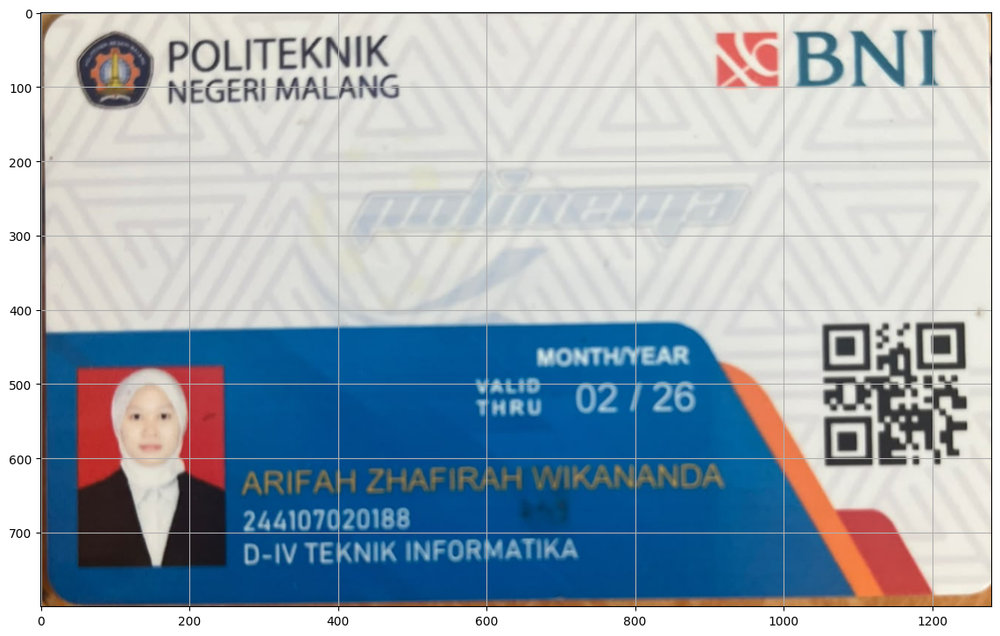

In [39]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

folder_induk = '/content/drive/MyDrive/Semester5/PCVK/P10_Arifah_04/'
folder_facedet = folder_induk + 'facedet/'

ktm_bgr = cv.imread(folder_facedet + 'KTM1d.jpeg')
ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
print('ukuran KTM:', ktm_bgr.shape)

plt.figure(figsize=(14, 9))
plt.imshow(ktm_rgb)
plt.grid(True)
plt.show()

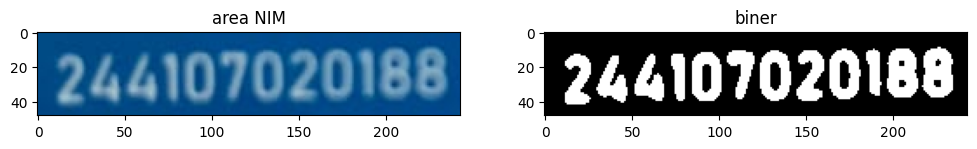

In [40]:
y1, y2 = 658, 706
x1, x2 = 262, 505

nim_rgb = ktm_rgb[y1:y2, x1:x2]
nim_gray = cv.cvtColor(nim_rgb, cv.COLOR_RGB2GRAY)
nim_gray = cv.GaussianBlur(nim_gray, (3, 3), 0)

_, biner = cv.threshold(nim_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

plt.figure(figsize=(12, 3))
plt.subplot(121), plt.imshow(nim_rgb), plt.title('area NIM')
plt.subplot(122), plt.imshow(biner, cmap='gray'), plt.title('biner')
plt.show()

jumlah karakter terdeteksi: 12


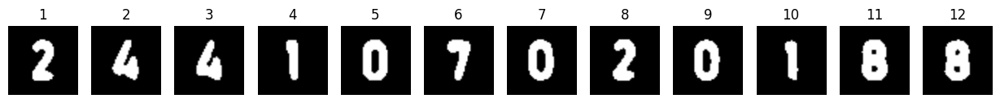

In [41]:
contours, hierarchy = cv.findContours(biner, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

tinggi_area = biner.shape[0]
kotak = []
for c in contours:
    x, y, w, h = cv.boundingRect(c)
    if h > 0.5 * tinggi_area:
        kotak.append((x, y, w, h))

kotak = sorted(kotak, key=lambda k: k[0])
print('jumlah karakter terdeteksi:', len(kotak))

karakter = []
for (x, y, w, h) in kotak:
    digit = biner[y:y+h, x:x+w]
    sisi = max(w, h) + 20
    kanvas = np.zeros((sisi, sisi), np.uint8)
    oy = (sisi - h) // 2
    ox = (sisi - w) // 2
    kanvas[oy:oy+h, ox:ox+w] = digit
    karakter.append(cv.resize(kanvas, (100, 100)))

fig, sumbu = plt.subplots(1, len(karakter), figsize=(len(karakter) * 1.3, 2.2))
for i, gambar in enumerate(karakter):
    sumbu[i].imshow(gambar, cmap='gray')
    sumbu[i].set_title(str(i + 1))
    sumbu[i].axis('off')
plt.show()

In [42]:
folder_simpan = folder_induk + 'dataset/testing/KTM/'
os.makedirs(folder_simpan, exist_ok=True)

for i, gambar in enumerate(karakter):
    cv.imwrite(folder_simpan + str(i + 1).zfill(2) + '.png', gambar)

print(sorted(os.listdir(folder_simpan)))

['01.png', '02.png', '03.png', '04.png', '05.png', '06.png', '07.png', '08.png', '09.png', '10.png', '11.png', '12.png', 'KTM1d.jpeg']
